# 03 · Respiración derivada del ECG (EDR), realizaciones y filtro de Wiener

**Pregunta de este notebook.** ¿Se puede obtener la respiración a partir del ECG, y cuánto se parece a la respiración medida? Es el objetivo específico 3 (`docs/objetivos_hipotesis.md`): la hipótesis necesita una señal respiratoria y la base solo tiene ECG en casi todos los registros.

1. Por qué el ECG lleva información de la respiración.
2. Cómo se mide: el área del QRS.
3. ¿La EDR sigue a la respiración medida? Latido a latido, en toda la noche y en frecuencia.
4. ¿Y durante la apnea?
5. Latidos como realizaciones y filtro de Wiener.
6. Qué variante de EDR usar: dos medidas (parecido con la respiración y detección de apnea) para cada variante.
7. La escala de la EDR: por qué se divide por el tamaño del QRS de cada registro.

Todo con registros de desarrollo. La comparación con la respiración usa los 8 registros que la tienen (a01–a04, b01, c01–c03).

In [1]:
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import butter, csd, sosfiltfilt, welch
from scipy.stats import mannwhitneyu

from src.config import ECG_FILTER, RESP_RECORDS, SPLIT_CSV
from src.data import load_apnea_labels, load_ecg, load_respiration
from src.features.coupling import downsample, resample_uniform, welch_spectra
from src.features.edr import beat_edr, beat_matrix, qrs_reference, validate_edr
from src.features.windows import centered_windows
from src.preprocessing.filters import apply_zero_phase, design_bandpass
from src.preprocessing.wiener import estimate_psds, extract_realizations, wiener_filter, wiener_from_beats
from src.qrs.beats import record_beats
from src.qrs.rr_clean import clean_rr, minute_quality
from src.viz.plots import ANCHO, APNEA, GRIS, NORMAL, save, setup, shade_apnea

setup()
split = pd.read_csv(SPLIT_CSV)
DEV = split[split.set == "dev"].record.tolist()
z = lambda v: (v - np.nanmean(v)) / np.nanstd(v)

def latidos(rec):
    """ECG, fs, picos R (detector propio, `02`) y latidos ectópicos (los que la limpieza del RR corrige)."""
    ecg, fs = load_ecg(rec)
    t_r = record_beats(rec)["t_r"]
    ect = np.r_[False, clean_rr(t_r)[2]]
    return ecg, fs, t_r, ect

## 1. Por qué el ECG lleva información de la respiración

El ECG mide, en la piel, el campo eléctrico que genera el corazón. Ese campo llega a los electrodos atravesando el tórax, y la respiración cambia el tórax en cada ciclo:

- **Cambia lo que hay entre el corazón y los electrodos.** Al inspirar, los pulmones se llenan de aire, que conduce mucho peor que los tejidos: aumenta la impedancia del tórax.
- **Cambia la posición del corazón.** Al inspirar baja el diafragma y el corazón rota y se desplaza; cambia el ángulo entre su eje eléctrico y la línea que une los electrodos de la derivación.

Los dos efectos cambian el **tamaño del QRS de un latido a otro**, al ritmo de la respiración (Moody et al., 1985). La forma del QRS no cambia, porque la activación del corazón es la misma; lo que cambia es cuánto de esa actividad "ve" la derivación. Para verlo, se superponen los QRS de 60 s de `c03` (un control, sin apnea), coloreados según el valor de la respiración medida por la banda del tórax en el instante de cada latido.

PosixPath('/home/user/TP-PSB-G8/informe/figuras/03_qrs_respiracion.png')

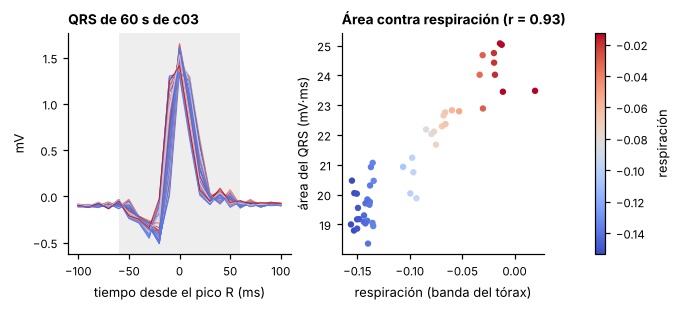

In [2]:
REC, T0 = "c03", 16140                    # tramo de 60 s de c03 (ver la sección 3 sobre cómo se eligió)
ecg, fs, t_r, ect = latidos(REC)
resp, fr = load_respiration(REC)
x = apply_zero_phase(ecg, design_bandpass(fs, *ECG_FILTER))
sel = (t_r >= T0) & (t_r < T0 + 60) & ~ect
c = np.rint(t_r[sel] * fs).astype(int)
_, sign = qrs_reference(x, np.rint(t_r * fs).astype(int), fs)
resp_lat = resp["Resp C"][np.rint(t_r[sel] * fr).astype(int)]
beats, _ = beat_matrix(x, c, fs, 0.10)
area = sign * beats[:, 4:17].sum(axis=1) / fs        # ±60 ms alrededor del pico

fig = plt.figure(figsize=(ANCHO, 2.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1.1, 1, 0.05], wspace=0.35)
ax0, ax1, cax = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])
cmap = plt.get_cmap("coolwarm")
norma = plt.Normalize(np.percentile(resp_lat, 5), np.percentile(resp_lat, 95))
t_ms = np.arange(-10, 11) * 10
for b, r in zip(beats, resp_lat):
    ax0.plot(t_ms, b, color=cmap(norma(r)), lw=0.7, alpha=0.8)
ax0.axvspan(-60, 60, color=GRIS, alpha=0.12, lw=0)
ax0.set(xlabel="tiempo desde el pico R (ms)", ylabel="mV", title="QRS de 60 s de c03")
ax1.scatter(resp_lat, 1000 * area, c=resp_lat, cmap=cmap, norm=norma, s=10)
r_ = np.corrcoef(resp_lat, area)[0, 1]
ax1.set(xlabel="respiración (banda del tórax)", ylabel="área del QRS (mV·ms)",
        title=f"Área contra respiración (r = {r_:.2f})")
fig.colorbar(plt.cm.ScalarMappable(norm=norma, cmap=cmap), cax=cax, label="respiración")
save(fig, "03_qrs_respiracion")

**Qué se ve.** Los QRS tienen todos la misma forma, pero su tamaño cambia con la respiración: cuando la banda del tórax marca valores altos (rojo), el QRS es más grande; con valores bajos (azul), más chico. A la derecha, el **área del QRS** de cada latido contra la respiración en ese instante: siguen una relación casi lineal. Esa área, latido a latido, es la **respiración derivada del ECG (EDR)**.

## 2. Cómo se mide: el área del QRS

Hay varias formas de medir el tamaño de cada QRS. Se comparan tres (Moody et al., 1985):

PosixPath('/home/user/TP-PSB-G8/informe/figuras/03_medidas_qrs.png')

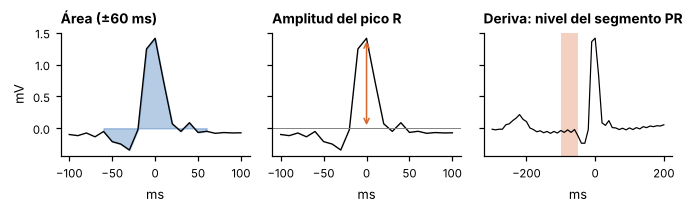

In [3]:
k = int(np.argmax(np.abs(area - np.median(area))))       # un latido cualquiera del tramo
b = beats[k]
fig, ax = plt.subplots(1, 3, figsize=(ANCHO, 2.0), sharey=True)
xr = ecg[c[k] - 30:c[k] + 21]; t_raw = np.arange(-30, 21) * 10
ax[0].plot(t_ms, b, color="black"); ax[0].fill_between(t_ms[4:17], 0, b[4:17], color=NORMAL, alpha=0.35)
ax[0].set(title="Área (±60 ms)", xlabel="ms", ylabel="mV")
ax[1].plot(t_ms, b, color="black"); ax[1].annotate("", xy=(t_ms[np.argmax(sign * b)], b[np.argmax(sign * b)]),
                                                  xytext=(t_ms[np.argmax(sign * b)], 0),
                                                  arrowprops=dict(arrowstyle="<->", color=APNEA))
ax[1].axhline(0, color=GRIS, lw=0.6)
ax[1].set(title="Amplitud del pico R", xlabel="ms")
ax[2].plot(t_raw, xr - np.median(xr), color="black", lw=0.8)
ax[2].axvspan(-100, -50, color=APNEA, alpha=0.3, lw=0)
ax[2].set(title="Deriva: nivel del segmento PR", xlabel="ms")
fig.tight_layout()
save(fig, "03_medidas_qrs")

- **Área del QRS**: la suma de la señal filtrada en ±60 ms alrededor del pico, con la polaridad del registro (en los registros con el QRS invertido se cambia el signo). Usa todo el complejo, así que es poco sensible a que el pico caiga entre dos muestras (a 100 Hz hay una muestra cada 10 ms) y al ruido de una muestra suelta.
- **Amplitud del pico R**: un solo valor por latido, refinado con la parábola de `02`.
- **Deriva de la línea de base**: el nivel del ECG crudo en el segmento PR (−100 a −50 ms), que también se mueve con la respiración. No mira el QRS, y es muy sensible al movimiento.

La EDR es una serie con un valor por latido, irregular en el tiempo. Para compararla con otras señales se interpola a una grilla de 2 Hz (spline cúbico), la misma que la serie RR.

## 3. ¿La EDR sigue a la respiración?

### Latido a latido

El tramo de la sección 1 se eligió como el minuto en que la EDR más se parece a la respiración en `c03`. Para no mostrar solo el mejor caso, abajo también un minuto **típico** (el de correlación mediana del registro).

PosixPath('/home/user/TP-PSB-G8/informe/figuras/03_edr_vs_respiracion.png')

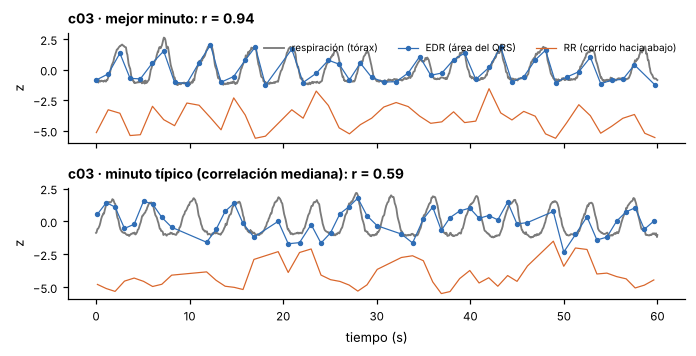

In [4]:
def edr_registro(rec, **kw):
    ecg_, fs_, t_r_, ect_ = latidos(rec)
    opciones = dict(method="area", exclude=ect_, hampel=True, prefilter=lambda s: wiener_from_beats(s, t_r_, fs_))
    opciones.update(kw)
    return beat_edr(ecg_, t_r_, fs_, **opciones), t_r_

(t_e, v_e), _ = edr_registro(REC)
corr_min = []
for t0 in range(0, int(t_e[-1]) - 60, 60):
    m = (t_e >= t0) & (t_e < t0 + 60)
    rc = resp["Resp C"][np.rint(t_e[m] * fr).astype(int)]
    if m.sum() > 30 and np.isfinite(rc).all():
        corr_min.append((np.corrcoef(v_e[m], rc)[0, 1], t0))
corr_min = sorted(corr_min)
tipico = corr_min[len(corr_min) // 2][1]

t_rr, rr, _ = clean_rr(t_r)
fig, axs = plt.subplots(2, 1, figsize=(ANCHO, 3.3), sharex=True)
for ax, t0, titulo in ((axs[0], T0, "mejor minuto"), (axs[1], tipico, "minuto típico (correlación mediana)")):
    i = slice(int(t0 * fr), int((t0 + 60) * fr))
    ax.plot(np.arange(i.stop - i.start) / fr, z(resp["Resp C"][i]), color=GRIS, lw=1.2, label="respiración (tórax)")
    m = (t_e >= t0) & (t_e < t0 + 60)
    ax.plot(t_e[m] - t0, z(v_e[m]), "o-", color=NORMAL, ms=2.5, lw=0.8, label="EDR (área del QRS)")
    mr = (t_rr >= t0) & (t_rr < t0 + 60)
    ax.plot(t_rr[mr] - t0, z(rr[mr]) - 4, color=APNEA, lw=0.8, label="RR (corrido hacia abajo)")
    rc = resp["Resp C"][np.rint(t_e[m] * fr).astype(int)]
    ax.set(title=f"{REC} · {titulo}: r = {np.corrcoef(v_e[m], rc)[0, 1]:.2f}", ylabel="z")
axs[0].legend(loc="upper right", ncol=3, fontsize=6.5)
axs[1].set_xlabel("tiempo (s)")
fig.tight_layout()
save(fig, "03_edr_vs_respiracion")

**Qué se ve.** La EDR sube y baja con cada respiración, un ciclo cada ~4 s. En el minuto típico la correlación es menor, pero el ritmo es el mismo. El RR también oscila con la respiración (arritmia sinusal respiratoria: el corazón se acelera al inspirar), pero es otra señal: refleja la regulación del ritmo cardíaco, no la mecánica del tórax.

### En toda la noche y en los 8 registros

Se repite la correlación minuto a minuto en todos los minutos de los 8 registros con respiración, con cada una de las tres señales respiratorias (tórax, abdomen y flujo nasal). Como referencia del azar se repite corriendo la EDR 10 minutos respecto de la respiración: así se conservan las dos señales pero se rompe su relación.

,real,azar
canal,,
Resp A,0.32,0.12
Resp C,0.34,0.13
Resp N,0.30,0.11


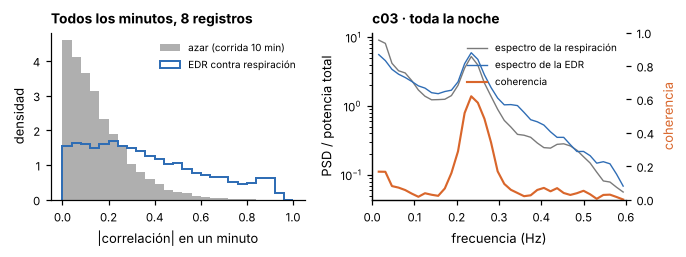

In [5]:
def corr_por_minuto(rec):
    (t_, v_), _ = edr_registro(rec)
    resp_, fr_ = load_respiration(rec)
    out = []
    for canal in ("Resp C", "Resp A", "Resp N"):
        s = resp_[canal]
        for t0 in range(0, int(t_[-1]) - 660, 60):
            m = (t_ >= t0) & (t_ < t0 + 60)
            if m.sum() < 30:
                continue
            idx = np.rint(t_[m] * fr_).astype(int)
            idx0 = np.rint((t_[m] + 600) * fr_).astype(int)
            if idx0[-1] >= len(s) or not (np.isfinite(s[idx]).all() and np.isfinite(s[idx0]).all()):
                continue
            out.append((rec, canal, abs(np.corrcoef(v_[m], s[idx])[0, 1]), abs(np.corrcoef(v_[m], s[idx0])[0, 1])))
    return out

with ProcessPoolExecutor(4) as ex:
    cm = pd.DataFrame([r for rr_ in ex.map(corr_por_minuto, RESP_RECORDS) for r in rr_],
                      columns=["record", "canal", "real", "azar"])

# Coherencia en frecuencia, toda la noche de c03
tu, vu = resample_uniform(t_e, v_e, 2.0)
r2 = downsample(np.nan_to_num(resp["Resp C"]), fr, 2.0)
ok = np.rint(tu * 2).astype(int) < len(r2)
ru = r2[np.rint(tu[ok] * 2).astype(int)]
f, pxy = csd(vu[ok], ru, fs=2, nperseg=128); _, pxx = welch(vu[ok], fs=2, nperseg=128); _, pyy = welch(ru, fs=2, nperseg=128)

fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 2.4))
bins = np.linspace(0, 1, 26)
ax[0].hist(cm.azar, bins=bins, color=GRIS, alpha=0.6, label="azar (corrida 10 min)", density=True)
ax[0].hist(cm.real, bins=bins, color=NORMAL, histtype="step", lw=1.3, label="EDR contra respiración", density=True)
ax[0].set(xlabel="|correlación| en un minuto", ylabel="densidad", title="Todos los minutos, 8 registros")
ax[0].legend(loc="upper right", fontsize=6.5)
banda_f = (f > 0) & (f <= 0.6)
ax[1].semilogy(f[banda_f], pyy[banda_f] / np.trapezoid(pyy, f), color=GRIS, label="espectro de la respiración")
ax[1].semilogy(f[banda_f], pxx[banda_f] / np.trapezoid(pxx, f), color=NORMAL, label="espectro de la EDR")
ax[1].set(xlim=(0, 0.6), xlabel="frecuencia (Hz)", ylabel="PSD / potencia total", title=f"{REC} · toda la noche")
axc = ax[1].twinx()
axc.plot(f[banda_f], (np.abs(pxy) ** 2 / (pxx * pyy))[banda_f], color=APNEA, lw=1.4, label="coherencia")
axc.set_ylim(0, 1); axc.set_ylabel("coherencia", color=APNEA)
h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = axc.get_legend_handles_labels()
ax[1].legend(h1 + h2, l1 + l2, loc="upper right", fontsize=6.5)
fig.tight_layout()
save(fig, "03_edr_toda_la_noche")
cm.groupby("canal")[["real", "azar"]].median().round(2)

**Qué se ve.** En todos los minutos de los 8 registros, la correlación entre la EDR y la respiración es claramente mayor que la del azar, con las tres señales respiratorias. No es perfecta: hay minutos con correlación baja (movimiento, cambios de posición, respiración irregular).

A la derecha, en frecuencia: los espectros de la EDR y de la respiración tienen el pico en el mismo lugar, la frecuencia respiratoria (~0,25 Hz), y ahí la **coherencia** es alta. Cómo leerlo:

- **La coherencia no compara la altura de los espectros.** Es C(f) = |S_xy(f)|² / (S_xx(f) · S_yy(f)): el espectro cruzado dividido por el producto de los dos espectros. Como se divide por la potencia de cada señal, no importa que una tenga más potencia que la otra ni que estén en unidades distintas (mV·ms y la unidad de la banda del tórax). Lo que mide es si, en esa frecuencia, **las dos oscilaciones mantienen la misma relación de amplitud y de fase a lo largo de la noche**: 1 si una se predice exactamente a partir de la otra con un filtro lineal, 0 si no tienen relación.
- **En ~0,25 Hz** las dos señales oscilan con cada respiración, siempre juntas: coherencia alta.
- **Por debajo de ~0,1 Hz** las dos tienen mucha potencia (las dos curvas están altas), pero son variaciones distintas —cambios de posición, deriva de la banda del tórax, variaciones lentas del QRS— que no se mueven juntas: coherencia baja. Que dos espectros se parezcan en una frecuencia no significa que las señales estén relacionadas ahí, y al revés.
- Los espectros se dibujan divididos por la potencia total de cada señal y en escala logarítmica, para poder ver los dos en el mismo eje; aun así sus alturas no se comparan entre sí.

## 4. ¿Y durante la apnea?

Durante una apnea obstructiva la persona intenta respirar contra la vía aérea cerrada: casi no entra aire, y después de cada episodio vienen varias respiraciones profundas. Lo que cambia con el ciclo de la apnea no es cada respiración, sino su **amplitud**. Por eso, para la apnea, la referencia es la **envolvente** de la respiración (la amplitud de cada respiración, medida como el valor eficaz en ventanas de 10 s), que es la señal con la que se puntúan las apneas en la polisomnografía. Si la EDR refleja la respiración, su componente lenta tiene que seguir a esa envolvente.

PosixPath('/home/user/TP-PSB-G8/informe/figuras/03_edr_apnea.png')

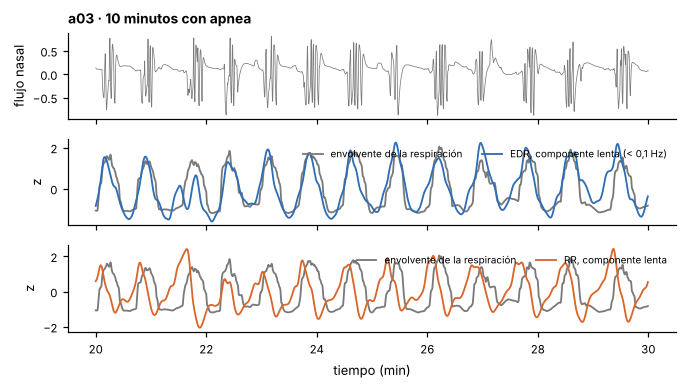

In [6]:
def envolvente(s, fs_, win=10):
    s = np.nan_to_num(s - np.nanmedian(s))
    n = int(win * fs_)
    return np.sqrt(np.convolve(s ** 2, np.ones(n) / n, mode="same"))

rec_a, m0 = "a03", 20
(t_a, v_a), t_ra = edr_registro(rec_a)
resp_a, fr_a = load_respiration(rec_a)
t_rra, rr_a, _ = clean_rr(t_ra)
lento = butter(2, 0.1, "low", fs=2, output="sos")
tu_a, vu_a = resample_uniform(t_a, v_a, 2.0)
tr_a, ru_a = resample_uniform(t_rra, rr_a, 2.0)
env_a = downsample(envolvente(resp_a["Resp N"], fr_a), fr_a, 2.0)
fig, axs = plt.subplots(3, 1, figsize=(ANCHO, 3.6), sharex=True)
i = slice(int(m0 * 60 * fr_a), int((m0 + 10) * 60 * fr_a))
axs[0].plot(np.arange(i.stop - i.start) / fr_a / 60 + m0, resp_a["Resp N"][i], color=GRIS, lw=0.5)
axs[0].set(ylabel="flujo nasal", title=f"{rec_a} · 10 minutos con apnea")
sel_e = (tu_a >= m0 * 60) & (tu_a < (m0 + 10) * 60)
axs[1].plot(tu_a[sel_e] / 60, z(env_a[np.rint(tu_a[sel_e] * 2).astype(int)]), color=GRIS, lw=1.2,
            label="envolvente de la respiración")
axs[1].plot(tu_a[sel_e] / 60, z(sosfiltfilt(lento, vu_a)[sel_e]), color=NORMAL, lw=1.2,
            label="EDR, componente lenta (< 0,1 Hz)")
axs[1].legend(loc="upper right", fontsize=6.5, ncol=2); axs[1].set_ylabel("z")
sel_r = (tr_a >= m0 * 60) & (tr_a < (m0 + 10) * 60)
axs[2].plot(tr_a[sel_r] / 60, z(env_a[np.rint(tr_a[sel_r] * 2).astype(int)]), color=GRIS, lw=1.2,
            label="envolvente de la respiración")
axs[2].plot(tr_a[sel_r] / 60, z(sosfiltfilt(lento, ru_a)[sel_r]), color=APNEA, lw=1.2, label="RR, componente lenta")
axs[2].legend(loc="upper right", fontsize=6.5, ncol=2); axs[2].set(ylabel="z", xlabel="tiempo (min)")
fig.tight_layout()
save(fig, "03_edr_apnea")

**Qué se ve.** Arriba, el flujo nasal: tramos casi sin flujo (las apneas) separados por ráfagas de respiraciones, cada ~40 s. Su envolvente (gris) sube y baja con ese ciclo. La componente lenta de la EDR (azul) oscila con el mismo ritmo: sube cuando se reanuda la respiración y baja durante la pausa. La del RR (naranja) también, pero adelantada: el RR es máximo (la frecuencia cardíaca más baja) al final de cada pausa y cae bruscamente cuando se reanuda la respiración, antes de que la envolvente llegue a su máximo. La potencia cruzada que usa la feature mide cuánto oscilan juntas las dos señales en la banda, sin importar ese desfase. Este es el fenómeno de la hipótesis: **RR y EDR oscilan juntos al ritmo del ciclo de la apnea**. Cuánto se parecen, medido en toda la noche, está en la sección 6.

## 5. Latidos como realizaciones y filtro de Wiener

La EDR sale de medir cada QRS, así que el ruido que caiga sobre el QRS (actividad muscular, interferencia) se mete en la EDR. El **filtro de Wiener** es el filtro lineal que, conociendo el espectro de la señal y el del ruido, minimiza el error cuadrático medio entre la señal filtrada y la señal limpia. Su respuesta en frecuencia es H(f) = S_s(f) / (S_s(f) + S_n(f)): deja pasar las frecuencias donde domina la señal y atenúa las que dominan el ruido.

El problema es estimar S_s y S_n. Acá se usa que **el ECG es casi periódico**: cada latido es una **realización** de la misma forma de onda más ruido. Se recortan todos los latidos del registro desde −250 ms hasta +400 ms alrededor del pico R (cubre la onda P, el QRS y casi toda la T; es el largo de un latido, no una ventana de análisis como la de 240 s de las features). El promedio de las realizaciones estima la señal y lo que queda en cada latido después de restarle el promedio, el ruido.

{'5-25 Hz': 0.95, '25-40 Hz': 0.7, '40-50 Hz': 0.3}


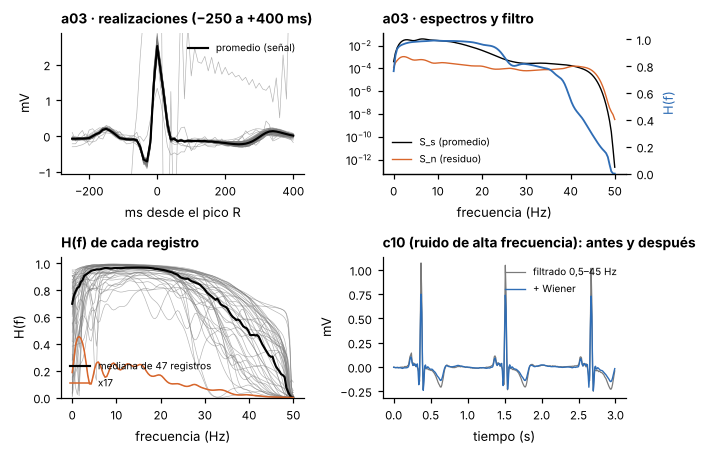

In [7]:
def wiener_registro(rec):
    ecg_, fs_, t_r_, _ = latidos(rec)
    x_ = apply_zero_phase(ecg_, design_bandpass(fs_, *ECG_FILTER))
    real_ = extract_realizations(x_, t_r_ * fs_, fs_)
    f_, ss_, sn_ = estimate_psds(real_, fs_)
    return rec, x_, real_, f_, ss_, sn_

with ProcessPoolExecutor(4) as ex:
    wr = {r[0]: r[1:] for r in ex.map(wiener_registro, DEV)}
fw = wr["a03"][2]
H_todos = pd.DataFrame({r: v[3] / (v[3] + v[4]) for r, v in wr.items()}, index=fw)

xw, real, _, s_s, s_n = wr["a03"]
t_real = np.arange(real.shape[1]) * 10 - 250
fig, ax = plt.subplots(2, 2, figsize=(ANCHO, 4.2))
for r_i in real[::300][:60]:
    ax[0, 0].plot(t_real, r_i, color=GRIS, lw=0.4, alpha=0.6)
ax[0, 0].plot(t_real, real.mean(axis=0), color="black", lw=1.4, label="promedio (señal)")
lim_y = np.percentile(real, [0.5, 99.5])
ax[0, 0].set(xlabel="ms desde el pico R", ylabel="mV", title="a03 · realizaciones (−250 a +400 ms)",
             ylim=(lim_y[0] - 0.3, lim_y[1] + 0.3))
ax[0, 0].legend(loc="upper right", fontsize=6.5)
ax[0, 1].semilogy(fw, s_s, color="black", label="S_s (promedio)")
ax[0, 1].semilogy(fw, s_n, color=APNEA, label="S_n (residuo)")
a2 = ax[0, 1].twinx(); a2.plot(fw, H_todos["a03"], color=NORMAL, lw=1.2); a2.set_ylim(0, 1.05)
a2.set_ylabel("H(f)", color=NORMAL)
ax[0, 1].set(xlabel="frecuencia (Hz)", title="a03 · espectros y filtro"); ax[0, 1].legend(loc="lower left", fontsize=6.5)
for r in H_todos.columns:
    ax[1, 0].plot(fw, H_todos[r], color=GRIS, lw=0.4, alpha=0.6)
ax[1, 0].plot(fw, H_todos.median(axis=1), color="black", lw=1.4, label="mediana de 47 registros")
ax[1, 0].plot(fw, H_todos["x17"], color=APNEA, lw=1.0, label="x17")
ax[1, 0].set(xlabel="frecuencia (Hz)", ylabel="H(f)", ylim=(0, 1.05), title="H(f) de cada registro")
ax[1, 0].legend(loc="lower left", fontsize=6.5)
xc = wr["c10"][0]
from src.preprocessing.wiener import wiener_filter as _wf
yc = _wf(xc, *wr["c10"][2:], 100.0)
# tramo de 3 s con ruido de alta frecuencia típico del registro (percentil 90 de la energía > 25 Hz)
hf = sosfiltfilt(butter(4, 25, "high", fs=100, output="sos"), xc) ** 2
e3 = hf[:len(hf) // 300 * 300].reshape(-1, 300).sum(1)
k3 = int(np.argsort(e3)[int(0.9 * len(e3))])
i = slice(k3 * 300, k3 * 300 + 300)
ax[1, 1].plot(np.arange(i.stop - i.start) / 100, xc[i], color=GRIS, lw=0.8, label="filtrado 0,5–45 Hz")
ax[1, 1].plot(np.arange(i.stop - i.start) / 100, yc[i], color=NORMAL, lw=0.9, label="+ Wiener")
ax[1, 1].set(xlabel="tiempo (s)", ylabel="mV", title="c10 (ruido de alta frecuencia): antes y después")
ax[1, 1].legend(loc="upper right", fontsize=6.5)
fig.tight_layout()
save(fig, "03_wiener")
banda_H = lambda a_, b_: float(H_todos[(fw >= a_) & (fw < b_)].mean().median())
print({f"{a_}-{b_} Hz": round(banda_H(a_, b_), 2) for a_, b_ in ((5, 25), (25, 40), (40, 50))})

**Qué se ve.** El promedio de las realizaciones es el latido "limpio"; las realizaciones individuales se apartan de él por el ruido. En un registro típico (`a03`) el espectro del promedio domina hasta ~25 Hz y H(f) es casi 1: el QRS, que tiene ahí casi toda su energía, pasa sin cambios. Por encima domina el residuo y el filtro atenúa. En los 47 registros pasa lo mismo (mediana de H: ~0,96 entre 5 y 25 Hz, ~0,7 entre 25 y 40 Hz, ~0,3 entre 40 y 50 Hz; los valores exactos se imprimen arriba). Abajo a la derecha, el registro con más atenuación por encima de 25 Hz (`c10`): Wiener le saca al QRS las componentes rápidas, donde domina el ruido, y el pico baja. Como el filtro es el mismo para todos los latidos, la variación del área de un latido a otro se conserva.

**La excepción es `x17`**: su H(f) es baja en todas las frecuencias. En `x17` la forma del QRS cambia a mitad de la noche (`02`: al principio es chico e invertido, después grande), así que el promedio de toda la noche no representa a ningún latido y el "residuo" es enorme. El filtro estimado así solo achica toda la señal. Es una limitación del método: supone que la forma del latido no cambia en la noche.

**Cuidado con un detalle:** el residuo también contiene la variación del QRS con la respiración, que es justamente lo que mide la EDR. Pero el filtro es lineal e invariante: aplica la misma ganancia a todos los latidos, así que si un QRS es 10 % más grande antes de filtrar, sigue siéndolo después. No borra la modulación respiratoria; solo cambia la forma de todos los QRS por igual. Si mejora o no la EDR se mide en la sección siguiente.

## 6. Qué variante de EDR usar

Para elegir no alcanza con que la EDR se parezca a la respiración en su ritmo de ~0,25 Hz: la hipótesis vive en la banda lenta del ciclo de la apnea (0,017–0,05 Hz, `01`). Por eso cada variante se mide de dos formas, una contra la respiración real y otra contra las etiquetas de apnea:

| Medida | Qué responde | Cómo se calcula | Registros |
|---|---|---|---|
| **A1. Coherencia con la respiración** | ¿Sigue cada respiración? | Coherencia EDR–respiración por Welch en ventanas de 120 s, promediada en frecuencia con el espectro de la respiración como peso (domina la banda respiratoria); media de los tres canales | los 8 con respiración |
| **A2. Coherencia con la envolvente** | ¿Sigue el ciclo de la apnea? | Coherencia EDR–envolvente de la respiración en 0,017–0,05 Hz, en toda la noche (segmentos de 120 s); media de los tres canales | los 4 con mucha apnea (a01–a04) |
| **B. Detección de apnea dentro de la noche** | ¿Separa los minutos con apnea de los normales? | Potencia de la EDR en 0,017–0,05 Hz (Welch, ventana de 240 s centrada en cada minuto); AUC entre minutos con apnea y normales **dentro de cada registro** | los 31 con al menos 20 minutos de cada tipo |

El **AUC** (área bajo la curva ROC) es la probabilidad de que un minuto con apnea elegido al azar tenga más potencia que un minuto normal elegido al azar: 0,5 es azar y 1 es separación perfecta. Medirlo dentro de cada registro evita que influya cuánta apnea o cuánta variabilidad tiene cada persona.

**Variantes.** Se parte del área del QRS de la primera versión y se agrega un cambio por vez; también se prueban las otras formas de medir el QRS:

- **Sin ectópicos**: se descartan los latidos que la limpieza del RR marcó (`02`). Un latido ectópico tiene otra forma y deja un valle profundo en el área (`01`, sección 6).
- **Sin atípicos**: se descartan los latidos cuya área se aparta más de 3 desvíos de la mediana de sus 11 vecinos (filtro de Hampel), con un piso de ruido para no marcar las crestas de la respiración (`src/features/edr.py`).
- **Wiener**: el área se mide sobre el ECG filtrado con Wiener (sección 5).
- **Amplitud R**, **deriva** y **área + deriva** (promedio de las dos estandarizadas), con la misma limpieza.

Como referencia se calculan las mismas medidas para la serie RR.

In [8]:
BANDA, W, FSU = (0.016, 0.051), 240, 2.0

def variantes(ect, wien):
    return {
        "área (primera versión)": dict(method="area"),
        "área sin ectópicos": dict(method="area", exclude=ect),
        "+ sin atípicos": dict(method="area", exclude=ect, hampel=True),
        "+ Wiener (propuesta)": dict(method="area", exclude=ect, hampel=True, prefilter=wien),
        "amplitud R": dict(method="amplitude", exclude=ect, hampel=True),
        "deriva de línea de base": dict(method="baseline", exclude=ect, hampel=True),
        "área + deriva": dict(method="combined", exclude=ect, hampel=True),
    }

def potencia_por_minuto(t, v, lab, q):
    minutos, inicios = centered_windows(len(lab), W, t[0], t[-1] + 1 / FSU)
    n = int(W * FSU); P, L = [], []
    for m, a in zip(minutos, inicios):
        if lab[m] < 0 or not q[m] <= 0.2:
            continue
        i = int(round((a - t[0]) * FSU)); s = v[i:i + n]
        if len(s) < n:
            continue
        f_, sxx, _, _ = welch_spectra(s, s, FSU, n // 2)
        P.append(np.log10(sxx[(f_ >= BANDA[0]) & (f_ <= BANDA[1])].mean())); L.append(lab[m])
    return np.array(P), np.array(L)

def evaluar(rec):
    ecg_, fs_, t_r_, ect_ = latidos(rec)
    t_rr_, rr_, corr_ = clean_rr(t_r_)
    lab = load_apnea_labels(rec); q = minute_quality(t_rr_, corr_, len(lab))
    wien = lambda s: wiener_from_beats(s, t_r_, fs_)
    series = {"RR (referencia)": resample_uniform(t_rr_, rr_, FSU)}
    for nombre, kw in variantes(ect_, wien).items():
        series[nombre] = resample_uniform(*beat_edr(ecg_, t_r_, fs_, **kw), FSU)
    resp_ = load_respiration(rec) if rec in RESP_RECORDS else None
    filas = []
    for nombre, (t, v) in series.items():
        fila = {"record": rec, "variante": nombre}
        P, L = potencia_por_minuto(t, v, lab, q)
        if (L == 1).sum() >= 20 and (L == 0).sum() >= 20:
            fila["B: AUC dentro de la noche"] = mannwhitneyu(P[L == 1], P[L == 0]).statistic / ((L == 1).sum() * (L == 0).sum())
        if resp_ is not None:
            r, fr_ = resp_; idx = np.rint(t * FSU).astype(int); a1, a2 = [], []
            for canal in ("Resp C", "Resp A", "Resp N"):
                r2 = downsample(r[canal], fr_, FSU); ok = idx < len(r2)
                a1.append(np.nanmedian(validate_edr(v[ok], r2[idx[ok]], FSU)))
                e = downsample(envolvente(r[canal], fr_), fr_, FSU)
                f_, pxy_ = csd(v[ok], e[idx[ok]], fs=FSU, nperseg=240)
                _, pvv = welch(v[ok], fs=FSU, nperseg=240); _, pee = welch(e[idx[ok]], fs=FSU, nperseg=240)
                mb = (f_ >= BANDA[0]) & (f_ <= BANDA[1])
                a2.append((np.abs(pxy_[mb]) ** 2 / (pvv[mb] * pee[mb])).mean())
            fila["A1: coherencia con la respiración"] = np.mean(a1)
            if (lab == 1).sum() >= 100:
                fila["A2: coherencia con la envolvente"] = np.mean(a2)
        filas.append(fila)
    return filas

with ProcessPoolExecutor(4) as ex:
    ev = pd.DataFrame([f_ for fs__ in ex.map(evaluar, DEV) for f_ in fs__])
medidas = ["A1: coherencia con la respiración", "A2: coherencia con la envolvente", "B: AUC dentro de la noche"]
orden_v = list(dict.fromkeys(ev.variante))
resumen = ev.groupby("variante")[medidas].agg(["mean", "median", "count"])
tabla = pd.DataFrame({
    "A1 (media, 8 reg.)": ev.groupby("variante")[medidas[0]].mean(),
    "A2 (media, 4 reg.)": ev.groupby("variante")[medidas[1]].mean(),
    "B (mediana, 31 reg.)": ev.groupby("variante")[medidas[2]].median(),
}).loc[orden_v]
base_v = "área (primera versión)"
for col, med in zip(tabla.columns, medidas):
    w = ev.pivot(index="record", columns="variante", values=med).dropna()
    tabla[col.split(" ")[0] + " mejora vs primera versión"] = [f"{int((w[v_] > w[base_v]).sum())}/{len(w)}" for v_ in orden_v]
tabla.round(3)

,"A1 (media, 8 reg.)","A2 (media, 4 reg.)","B (mediana, 31 reg.)",A1 mejora vs primera versión,A2 mejora vs primera versión,B mejora vs primera versión
variante,,,,,,
RR (referencia),0.572,0.559,0.924,5/8,4/4,31/31
área (primera versión),0.535,0.228,0.788,0/8,0/4,0/31
área sin ectópicos,0.540,0.264,0.796,4/8,2/4,18/31
+ sin atípicos,0.536,0.287,0.803,1/8,2/4,20/31
+ Wiener (propuesta),0.545,0.290,0.810,2/8,2/4,19/31
amplitud R,0.336,0.209,0.870,0/8,2/4,24/31
deriva de línea de base,0.456,0.218,0.618,3/8,2/4,6/31
área + deriva,0.498,0.285,0.695,3/8,4/4,7/31


Las diferencias entre variantes son chicas. ¿Son reales o ruido? Se compara cada variante con la anterior **en los mismos registros** (diferencia pareada) y se calcula un intervalo de confianza al 95 % remuestreando personas (bootstrap por sujeto, 4000 remuestreos): si el intervalo no incluye el cero, la mejora no se explica por qué registros tocaron.

In [9]:
sujeto = split.set_index("record").subject
rng_b = np.random.default_rng(2026)
pasos = [("área sin ectópicos", "área (primera versión)"), ("+ sin atípicos", "área sin ectópicos"),
         ("+ Wiener (propuesta)", "+ sin atípicos"), ("+ Wiener (propuesta)", "área (primera versión)")]
filas_p = []
for med in medidas:
    w = ev.pivot(index="record", columns="variante", values=med).dropna()
    for a_, b_ in pasos:
        d = (w[a_] - w[b_]); suj = sujeto[d.index].to_numpy(); us = np.unique(suj)
        boot = [np.mean(np.concatenate([d.to_numpy()[suj == u] for u in rng_b.choice(us, len(us))])) for _ in range(4000)]
        lo, hi = np.percentile(boot, [2.5, 97.5])
        filas_p.append({"medida": med.split(":")[0], "comparación": f"{a_}  vs  {b_}", "diferencia media": d.mean(),
                        "IC 95 %": f"{lo:+.3f} a {hi:+.3f}", "registros que mejoran": f"{int((d > 0).sum())}/{len(d)}"})
pd.DataFrame(filas_p).set_index(["medida", "comparación"]).round(3)

diferencia media  \
medida comparación                                                          
A1     área sin ectópicos  vs  área (primera versión)               0.005   
       + sin atípicos  vs  área sin ectópicos                      -0.005   
       + Wiener (propuesta)  vs  + sin atípicos                     0.009   
       + Wiener (propuesta)  vs  área (primera versión)             0.010   
A2     área sin ectópicos  vs  área (primera versión)               0.036   
       + sin atípicos  vs  área sin ectópicos                       0.023   
       + Wiener (propuesta)  vs  + sin atípicos                     0.003   
       + Wiener (propuesta)  vs  área (primera versión)             0.062   
B      área sin ectópicos  vs  área (primera versión)               0.020   
       + sin atípicos  vs  área sin ectópicos                       0.010   
       + Wiener (propuesta)  vs  + sin atípicos                     0.007   
       + Wiener (propuesta)  vs  área (primera versión)             0.036   

                                                                 IC 95 %  \
medida comparación                                                         
A1     área sin ectópicos  vs  área (primera versión)    -0.026 a +0.043   
       + sin atípicos  vs  área sin ectópicos            -0.014 a +0.004   
       + Wiener (propuesta)  vs  + sin atípicos          -0.003 a +0.027   
       + Wiener (propuesta)  vs  área (primera versión)  -0.022 a +0.048   
A2     área sin ectópicos  vs  área (primera versión)    -0.011 a +0.114   
       + sin atípicos  vs  área sin ectópicos            -0.002 a +0.048   
       + Wiener (propuesta)  vs  + sin atípicos          -0.005 a +0.015   
       + Wiener (propuesta)  vs  área (primera versión)  -0.005 a +0.144   
B      área sin ectópicos  vs  área (primera versión)    -0.001 a +0.056   
       + sin atípicos  vs  área sin ectópicos            -0.011 a +0.037   
       + Wiener (propuesta)  vs  + sin atípicos          -0.004 a +0.019   
       + Wiener (propuesta)  vs  área (primera versión)  +0.005 a +0.087   

                                                        registros que mejoran  
medida comparación                                                             
A1     área sin ectópicos  vs  área (primera versión)                     4/8  
       + sin atípicos  vs  área sin ectópicos                             2/8  
       + Wiener (propuesta)  vs  + sin atípicos                           5/8  
       + Wiener (propuesta)  vs  área (primera versión)                   2/8  
A2     área sin ectópicos  vs  área (primera versión)                     2/4  
       + sin atípicos  vs  área sin ectópicos                             3/4  
       + Wiener (propuesta)  vs  + sin atípicos                           2/4  
       + Wiener (propuesta)  vs  área (primera versión)                   2/4  
B      área sin ectópicos  vs  área (primera versión)                   18/31  
       + sin atípicos  vs  área sin ectópicos                           19/31  
       + Wiener (propuesta)  vs  + sin atípicos                         20/31  
       + Wiener (propuesta)  vs  área (primera versión)                 19/31

PosixPath('/home/user/TP-PSB-G8/informe/figuras/03_variantes_edr.png')

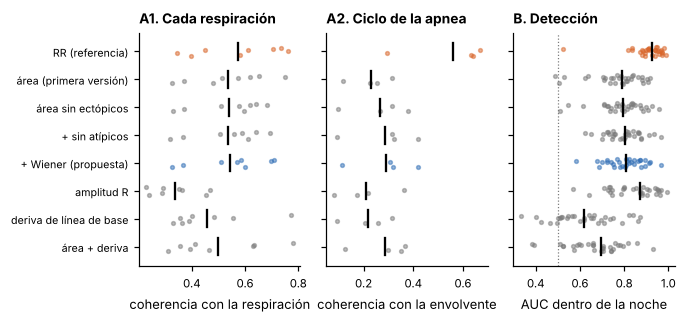

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(ANCHO, 3.0), sharey=True)
ys = np.arange(len(orden_v))[::-1]
for ax, med, titulo in zip(axs, medidas, ["A1. Cada respiración", "A2. Ciclo de la apnea", "B. Detección"]):
    for y, v_ in zip(ys, orden_v):
        vals = ev.loc[ev.variante == v_, med].dropna()
        color = APNEA if v_.startswith("RR") else (NORMAL if "propuesta" in v_ else GRIS)
        ax.scatter(vals, np.full(len(vals), y) + np.random.default_rng(0).uniform(-0.15, 0.15, len(vals)),
                   s=6, color=color, alpha=0.5)
        cen = vals.median() if med.startswith("B") else vals.mean()
        ax.plot([cen, cen], [y - 0.3, y + 0.3], color="black", lw=1.5)
    ax.set(title=titulo, xlabel=med.split(": ")[1])
axs[0].set_yticks(ys); axs[0].set_yticklabels(orden_v, fontsize=7)
axs[2].axvline(0.5, color=GRIS, ls=":", lw=0.8)
fig.tight_layout()
save(fig, "03_variantes_edr")

**Qué se ve** (cada punto es un registro; la raya, la media en A1 y A2 y la mediana en B):

- **El área del QRS es la mejor forma de medir.** La deriva y la combinación área + deriva empeoran las dos medidas: el empate de la primera versión se resuelve a favor del área.
- **La amplitud R detecta mejor la apnea pero no sigue la respiración** (A1 mucho más baja). Lo que capta en la banda lenta no es la respiración: no sirve como EDR para esta hipótesis, que necesita una señal respiratoria. Por eso hacían falta las dos medidas.
- **Limpiar y filtrar suma de a poco, pero cada paso por separado no se distingue del ruido.** Sacar los ectópicos, sacar los atípicos y aplicar Wiener mejoran las medias, pero con 31, 8 y 4 registros ninguno de los intervalos de cada paso excluye el cero. **Los tres juntos**, contra la primera versión, sí mejoran la detección de apnea (B: +0,036 de AUC, con un intervalo que no incluye el cero), y las dos coherencias con la respiración quedan iguales o algo mejor (con tan pocos registros no se puede afirmar más).
- **La serie RR separa los minutos mejor que cualquier EDR** (AUC ~0,92 contra ~0,81) y sigue mejor la envolvente de la respiración. Es la pregunta secundaria del trabajo: si la EDR aporta algo sobre el RR se mide en `04`.

**Decisión** (regla: se adopta una variante si mejora al menos dos de las tres medidas y no empeora claramente la tercera): **EDR = área del QRS sobre el ECG filtrado con Wiener, sin latidos ectópicos ni atípicos.** Frente a la primera versión mejora la detección dentro de la noche y no empeora el parecido con la respiración. Cada paso tiene además un motivo físico: un latido ectópico o un artefacto no es respiración, y Wiener reduce el ruido sobre el QRS sin cambiar su modulación. Queda en el pipeline (`src/features/build.py`), en su forma relativa (sección 7).

## 7. La escala de la EDR

La EDR mide el área del QRS en mV·ms. Pero el tamaño del QRS cambia mucho de una persona a otra por razones que no tienen que ver con la respiración: la anatomía, la contextura y dónde quedaron los electrodos (`01`: hay registros con QRS de 0,7 mV y otros de más de 4 mV). Si la respiración cambia el QRS en una **proporción** parecida en todos, la oscilación de la EDR en mV·ms va a ser más grande en las personas con QRS grande, solo por eso. Con un único umbral para todos, eso importa.

Se mide en los 47 registros de desarrollo, sin etiquetas:

- **Tamaño del QRS**: la mediana del **área sin signo** de cada latido (la suma del valor absoluto en ±60 ms). No sirve la mediana del área con signo: en un QRS con una onda R positiva y una S negativa las dos partes se cancelan, y el área con signo queda chica aunque el QRS sea grande.
- **Variación respiratoria de la EDR**: en cada minuto, cuánto varía el área de un latido a otro (desvío estándar); se toma la mediana de todos los minutos de la noche. Dentro de un minuto, lo que más mueve el área es la respiración (sección 3).

{'variación respiratoria (mV·ms)': np.float64(0.7), 'variación respiratoria relativa (%)': np.float64(-0.02)}


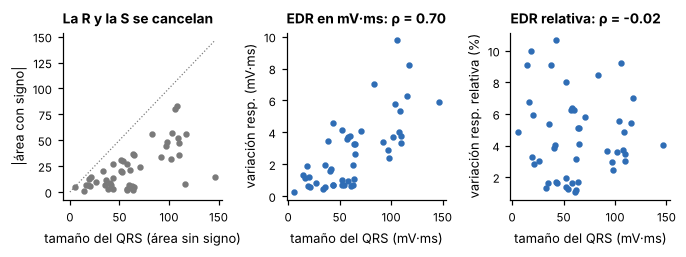

In [11]:
def escala_registro(rec):
    ecg_, fs_, t_r_, ect_ = latidos(rec)
    t_, v_rel, esc = beat_edr(ecg_, t_r_, fs_, "area", exclude=ect_, hampel=True,
                              prefilter=lambda s: wiener_from_beats(s, t_r_, fs_), relative=True, return_scale=True)
    v_abs = v_rel * esc
    m = (t_ // 60).astype(int)
    return {"record": rec, "tamaño (área sin signo, mV·ms)": 1000 * esc,
            "área con signo (mediana, mV·ms)": 1000 * float(np.median(v_abs)),
            "variación respiratoria (mV·ms)": 1000 * float(pd.Series(v_abs).groupby(m).std().median()),
            "variación respiratoria relativa (%)": 100 * float(pd.Series(v_rel).groupby(m).std().median()),
            "t": t_, "v_abs": v_abs, "v_rel": v_rel}

with ProcessPoolExecutor(4) as ex:
    esc_reg = list(ex.map(escala_registro, DEV))
esc_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("t", "v_abs", "v_rel")} for r in esc_reg]).set_index("record")
series_esc = {r["record"]: r for r in esc_reg}
from scipy.stats import spearmanr

tam = esc_df["tamaño (área sin signo, mV·ms)"]
fig, ax = plt.subplots(1, 3, figsize=(ANCHO, 2.4))
ax[0].scatter(tam, esc_df["área con signo (mediana, mV·ms)"].abs(), s=10, color=GRIS)
ax[0].plot([0, tam.max()], [0, tam.max()], color=GRIS, ls=":", lw=0.8)
ax[0].set(xlabel="tamaño del QRS (área sin signo)", ylabel="|área con signo|", title="La R y la S se cancelan")
for a_, col, titulo in ((ax[1], "variación respiratoria (mV·ms)", "EDR en mV·ms"),
                        (ax[2], "variación respiratoria relativa (%)", "EDR relativa")):
    rho = spearmanr(tam, esc_df[col])[0]
    a_.scatter(tam, esc_df[col], s=10, color=NORMAL)
    a_.set(xlabel="tamaño del QRS (mV·ms)", ylabel=col.replace("variación respiratoria", "variación resp."),
           title=f"{titulo}: ρ = {rho:.2f}")
fig.tight_layout()
save(fig, "03_escala_edr")
print({c: round(spearmanr(tam, esc_df[c])[0], 2) for c in ["variación respiratoria (mV·ms)", "variación respiratoria relativa (%)"]})

**Qué se ve.**
- **Izquierda**: en muchos registros el área con signo es mucho más chica que el área sin signo (los puntos quedan lejos de la diagonal): la R y la S se cancelan. Por eso la escala es el área **sin** signo.
- **Centro**: la variación respiratoria de la EDR en mV·ms **crece con el tamaño del QRS**. Las personas con QRS grande tienen una EDR que oscila más, aunque respiren igual.
- **Derecha**: dividida por el tamaño del QRS de su registro, la variación **deja de depender del tamaño**. La respiración cambia el QRS en una proporción, y esa proporción es comparable entre personas.

Así se ve en dos registros concretos: el de QRS más grande y el de QRS más chico entre los que tienen una variación respiratoria relativa típica (cerca de la mediana), en un minuto de respiración normal de cada uno. Se dibuja cuánto se aparta el área de cada latido de su valor típico en ese minuto.

PosixPath('/home/user/TP-PSB-G8/informe/figuras/03_escala_ejemplo.png')

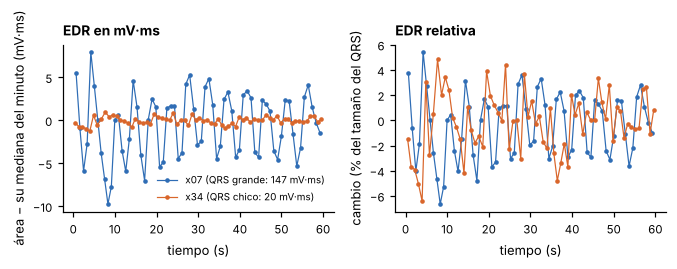

In [12]:
rel_ = esc_df["variación respiratoria relativa (%)"]
tipicos = esc_df[(rel_ > 0.75 * rel_.median()) & (rel_ < 1.25 * rel_.median()) & (esc_df.index != "x17")]
grande, chico = tipicos["tamaño (área sin signo, mV·ms)"].idxmax(), tipicos["tamaño (área sin signo, mV·ms)"].idxmin()
fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 2.4), sharex=True)
for rec_, color in ((grande, NORMAL), (chico, APNEA)):
    r_ = series_esc[rec_]; lab_ = load_apnea_labels(rec_)
    normales_ = [mm for mm in range(60, len(lab_) - 60) if (lab_[mm - 2:mm + 3] == 0).all()]
    t0 = 60 * (normales_[len(normales_) // 2] if normales_ else 120)
    sel_ = (r_["t"] >= t0) & (r_["t"] < t0 + 60)
    etiqueta = f"{rec_} (QRS {'grande' if rec_ == grande else 'chico'}: {tam[rec_]:.0f} mV·ms)"
    va, vr = r_["v_abs"][sel_], r_["v_rel"][sel_]
    ax[0].plot(r_["t"][sel_] - t0, 1000 * (va - np.median(va)), "o-", ms=2, lw=0.8, color=color, label=etiqueta)
    ax[1].plot(r_["t"][sel_] - t0, 100 * (vr - np.median(vr)), "o-", ms=2, lw=0.8, color=color, label=etiqueta)
ax[0].set(xlabel="tiempo (s)", ylabel="área − su mediana del minuto (mV·ms)", title="EDR en mV·ms")
ax[1].set(xlabel="tiempo (s)", ylabel="cambio (% del tamaño del QRS)", title="EDR relativa")
ax[0].legend(loc="lower right", fontsize=6.5)
fig.tight_layout()
save(fig, "03_escala_ejemplo")

En mV·ms, la EDR del registro con QRS chico oscila mucho menos que la del registro con QRS grande, aunque los dos respiran con normalidad. Expresada como porcentaje del tamaño del QRS, las dos oscilaciones son comparables.

**Decisión: la EDR es relativa.** El área con signo de cada latido se divide por el tamaño típico del QRS de su registro (la mediana del área sin signo). No usa etiquetas, se calcula con los latidos del propio registro y se puede aplicar igual en test. Dentro de una noche no cambia nada (es dividir por una constante: el orden de los minutos y las coherencias de la sección 6 quedan iguales); lo que cambia es la comparación **entre personas**, y su efecto en la detección se mide en `04`.